# 01 Data audit (S2)

**Owner:** Sumaiya · **Due:** CP1 · **Covers:** proposal feedback FB2, Lec 2–3

What's in the raw Meituan file, what's wrong with it, and how many rows each problem affects. It ends with the
before → after table for the report. Nothing here changes the data; the rules live in `common/clean.py`.

Column meanings come from Meituan's data description (Tables 1–2) and supplementary document (README §2).

## 0. Source and collection
| | |
|---|---|
| **Source** | Meituan, released for the INFORMS TSL Data-Driven Research Challenge (2024); file `all_waybill_info_meituan_0322.csv` |
| **Collection** | Logged automatically by Meituan's dispatch system: one row per waybill (an attempt to assign an order to a courier), with timestamps for each step |
| **Scope** | One city, 8 days (17–24 Oct 2022), 23 delivery areas, 4,962 restaurants, 4,955 couriers |
| **Size** | 654,343 rows × 23 columns (122 MB unzipped) |
| **Privacy** | IDs anonymised; coordinates shifted (not scaled) |
| **Licence** | CC BY-NC 4.0, no redistribution. Acknowledgement: *"This research was supported by data provided by Meituan."* |

The raw file is never modified; every rule is in `common/clean.py`.

In [1]:
import sys; sys.path.insert(0, "..")   # so `common` imports work from notebooks/
import numpy as np
import pandas as pd
from common.data import load_raw, load_table

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
raw = load_raw()

## 1. The four commands (Lec 3)
`shape`, `info`, `describe`, `isna().sum()` on the raw file, before any cleaning.

In [2]:
raw.shape

(654343, 23)

In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
Index: 654343 entries, 0 to 654342
Data columns (total 23 columns):
 #   Column                      Non-Null Count   Dtype
---  ------                      --------------   -----
 0   dt                          654343 non-null  int64
 1   order_id                    654343 non-null  int64
 2   waybill_id                  654343 non-null  int64
 3   courier_id                  654343 non-null  int64
 4   da_id                       654343 non-null  int64
 5   is_courier_grabbed          654343 non-null  int64
 6   is_weekend                  654343 non-null  int64
 7   estimate_arrived_time       654343 non-null  int64
 8   is_prebook                  654343 non-null  int64
 9   poi_id                      654343 non-null  int64
 10  sender_lng                  654343 non-null  int64
 11  sender_lat                  654343 non-null  int64
 12  recipient_lng               654343 non-null  int64
 13  recipient_lat               654343 non-null  int6

In [4]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
dt,654343.0,2.022102e+07,2.269893e+00,2.022102e+07,2.022102e+07,2.022102e+07,2.022102e+07,2.022102e+07
order_id,654343.0,2.683465e+05,1.648736e+05,0.000000e+00,1.232425e+05,2.603610e+05,4.094275e+05,5.685450e+05
waybill_id,654343.0,3.271710e+05,1.888927e+05,0.000000e+00,1.635855e+05,3.271710e+05,4.907565e+05,6.543420e+05
courier_id,654343.0,1.776802e+03,1.180778e+03,0.000000e+00,7.760000e+02,1.632000e+03,2.648000e+03,4.954000e+03
da_id,654343.0,6.320054e+00,5.626747e+00,0.000000e+00,1.000000e+00,5.000000e+00,9.000000e+00,2.200000e+01
is_courier_grabbed,654343.0,8.688807e-01,3.375310e-01,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
is_weekend,654343.0,2.722716e-01,4.451293e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00
estimate_arrived_time,654343.0,1.666300e+09,1.966780e+05,1.665938e+09,1.666148e+09,1.666324e+09,1.666486e+09,1.666641e+09
is_prebook,654343.0,3.684459e-02,1.883803e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
poi_id,654343.0,1.077935e+03,9.221813e+02,0.000000e+00,3.520000e+02,8.360000e+02,1.532000e+03,4.961000e+03


In [5]:
raw.isna().sum()

dt                            0
order_id                      0
waybill_id                    0
courier_id                    0
da_id                         0
is_courier_grabbed            0
is_weekend                    0
estimate_arrived_time         0
is_prebook                    0
poi_id                        0
sender_lng                    0
sender_lat                    0
recipient_lng                 0
recipient_lat                 0
grab_lng                      0
grab_lat                      0
dispatch_time                 0
grab_time                     0
fetch_time                    0
arrive_time                   0
estimate_meal_prepare_time    0
order_push_time               0
platform_order_time           0
dtype: int64

**Reading:** 654,343 rows × 23 columns, all integers, no NaNs. That's suspicious: several timestamps have a
minimum of 0 (1 Jan 1970). Missing values are stored as 0, so `isna()` can't see them. Section 2 counts them.

## 2. Sentinel zeros: hidden missing values

In [6]:
zeros = (raw == 0).sum()
zeros[zeros > 0].sort_values(ascending=False).to_frame("zeros")

,zeros
is_prebook,630234
is_weekend,476184
da_id,148903
arrive_time,85798
is_courier_grabbed,85797
grab_lng,85797
grab_lat,85797
grab_time,85797
fetch_time,85797
estimate_meal_prepare_time,9907


In [7]:
# Are the zeros in grab/fetch/arrive time exactly the refused dispatch attempts?
refused = raw["is_courier_grabbed"] == 0
for col in ["grab_time", "fetch_time", "arrive_time", "grab_lng", "grab_lat"]:
    z = raw[col] == 0
    print(f"{col:12s} zeros {z.sum():>7,}  | of which refused {(z & refused).sum():>7,}  | accepted {(z & ~refused).sum():>3}")

grab_time    zeros  85,797  | of which refused  85,797  | accepted   0
fetch_time   zeros  85,797  | of which refused  85,797  | accepted   0
arrive_time  zeros  85,798  | of which refused  85,797  | accepted   1
grab_lng     zeros  85,797  | of which refused  85,797  | accepted   0
grab_lat     zeros  85,797  | of which refused  85,797  | accepted   0


In [8]:
# Missing estimated prep time: raw vs accepted orders only
prep0 = raw["estimate_meal_prepare_time"] == 0
print(f"prep time = 0, all raw rows:      {prep0.sum():,}")
print(f"prep time = 0, refused attempts:  {(prep0 & refused).sum():,}")
print(f"prep time = 0, accepted orders:   {(prep0 & ~refused).sum():,}  ({(prep0 & ~refused).sum() / (~refused).sum():.1%})")

prep time = 0, all raw rows:      9,907
prep time = 0, refused attempts:  33
prep time = 0, accepted orders:   9,874  (1.7%)


**Reading:** the zeros are three different things.

1. **Steps that never happened (85,797 rows).** Grab, fetch and arrival times and the grab location are 0 on
   exactly the refused attempts, plus one accepted order with no arrival time. Meituan's supplementary doc
   (§2.4) says refused waybills look like this. C1 drops them.
2. **Real missing values.** Estimated meal-ready time is 0 for 9,874 accepted orders (1.7%). It's the only zero
   that hits a model input, so it's imputed (C6) and flagged (F3). §4 finds a second missing code in this column.
3. **Not missing.** IDs start at 0, and 0 means "no" in the flag columns.

## 3. Data dictionary

In [9]:
# Facts per column, computed. Zeros are excluded from min/max so sentinels don't hide the real range.
after_order = {"courier_id", "dispatch_time", "grab_time", "fetch_time", "arrive_time",
               "grab_lng", "grab_lat", "is_courier_grabbed", "estimate_arrived_time"}
facts = pd.DataFrame({
    "unique": raw.nunique(),
    "zeros": (raw == 0).sum(),
    "min (non-zero)": raw[raw != 0].min(),
    "max": raw.max(),
    "known at order time": ["no" if c in after_order else "yes" for c in raw.columns],
})
facts

,unique,zeros,min (non-zero),max,known at order time
dt,8,0,2.022102e+07,20221024,yes
order_id,568546,2,1.000000e+00,568545,yes
waybill_id,654343,1,1.000000e+00,654342,yes
courier_id,4955,33,1.000000e+00,4954,no
da_id,23,148903,1.000000e+00,22,yes
is_courier_grabbed,2,85797,1.000000e+00,1,no
is_weekend,2,476184,1.000000e+00,1,yes
estimate_arrived_time,291719,0,1.665938e+09,1666641420,no
is_prebook,2,630234,1.000000e+00,1,yes
poi_id,4962,757,1.000000e+00,4961,yes


One row is a **waybill**, one attempt to assign an order to a courier. A refused order gets a new waybill, so an
order can appear more than once. "Known at order time" decides whether a column can be a model input (C7).

| Column | Meaning | Type | Units | Valid range (observed) | Issues | Known at order time? |
|---|---|---|---|---|---|---|
| `dt` | Date of the order (Meituan: "date of order creation") | date (int) | YYYYMMDD | 20221017–20221024 (8 days) | differs from the placement date for 1,758 orders, 1,618 of them pre-booked (§4) | yes |
| `order_id` | Anonymised order identifier | id (int) | id | 0–568,545 | repeats when a waybill is refused | yes |
| `waybill_id` | Anonymised waybill (assignment attempt) identifier; a new one is created each time an order re-enters dispatch | id (int) | id | 0–654,342, unique | none | yes |
| `courier_id` | Courier the waybill was assigned to at dispatch | id (int) | id | 0–4,954 | | **no**: assigned after the order (leakage) |
| `da_id` | Area ID ("business district"). Linked to geography *and* order type, so areas can overlap (supplementary §2.6) | categorical id (int) | id | 0–22 (23 areas) | 0 is a real area; areas are not clean geographic districts | yes |
| `is_courier_grabbed` | Whether the courier accepted the waybill | binary | 0/1 | 0/1 | 0 = refused attempt (85,797) | **no** |
| `is_weekend` | Whether the order date is a weekend | binary | 0/1 | 0/1 | follows the placement date, not `dt` (§4) | yes |
| `estimate_arrived_time` | Platform's **promised** delivery time | timestamp (int) | Unix s | ≥ order time | padded: never < 30 min after the order | **no**: baseline only, never an input |
| `is_prebook` | Whether the order is pre-booked for a later time | binary | 0/1 | 0/1 | different population (22,181 accepted) | yes |
| `poi_id` | Anonymised merchant (restaurant) identifier | categorical id (int) | id | 0–4,961 | 4,962 levels: high cardinality | yes |
| `sender_lat`, `sender_lng` | Pickup (restaurant) location | coordinate (int) | degrees × 1e6 | lat 45.76–46.07, lng 174.48–174.99 | shifted for privacy (not scaled): distances valid, places not real | yes |
| `recipient_lat`, `recipient_lng` | Delivery (customer) location | coordinate (int) | degrees × 1e6 | lat 45.73–46.07, lng 174.39–174.99 | shifted for privacy | yes |
| `grab_lat`, `grab_lng` | Courier's location when the waybill was assigned | coordinate (int) | degrees × 1e6 | as above | 0 on refused attempts | **no** |
| `dispatch_time` | When the waybill was assigned to a courier (who may refuse) | timestamp (int) | Unix s | ≥ order time | 0 in 1 row | **no** |
| `grab_time` | When the courier accepted the waybill | timestamp (int) | Unix s | ≥ dispatch time | 0 on refused attempts | **no** |
| `fetch_time` | When the courier picked the food up | timestamp (int) | Unix s | ≥ grab time | 0 on refused attempts | **no** |
| `arrive_time` | When the order was delivered | timestamp (int) | Unix s | ≥ fetch time | 0 on refused attempts + 1 accepted order | **no**: end point of the target |
| `estimate_meal_prepare_time` | **Estimated** meal-ready time (supplementary §2.5: an estimate, not when the meal was actually ready) | timestamp (int) | Unix s | ≥ order time | 0 = missing (9,874); under 5 min = a default (75,361 modelling orders, C2b); pickup beats 55% of real estimates | yes (assumed; the file doesn't say when it's set) |
| `order_push_time` | When the order entered the dispatch system for assignment | timestamp (int) | Unix s | ≥ order time | none | yes |
| `platform_order_time` | When the order was created (placed) | timestamp (int) | Unix s | 11–24 Oct 2022 (pre-booked orders are placed up to 6 days ahead; normal orders from 16 Oct 23:39) | none | yes: start point of the target |

**Target:** `delivery_min = (arrive_time − platform_order_time) / 60`.

## 4. Every quirk, counted

In [10]:
acc = raw[~refused]
dur = (acc["arrive_time"] - acc["platform_order_time"]) / 60   # minutes; meaningless where arrive_time = 0
has_arrival = acc["arrive_time"] != 0
quirks = {
    "refused dispatch attempts": refused.sum(),
    "accepted orders": len(acc),
    "accepted order_id unique": acc["order_id"].is_unique,
    "share of refused attempts whose order was accepted by someone": raw.loc[refused, "order_id"].isin(acc["order_id"]).mean(),
    "accepted orders with no arrival time": (~has_arrival).sum(),
    "pre-booked orders (accepted)": acc["is_prebook"].sum(),
    "deliveries > 180 min": ((dur > 180) & has_arrival).sum(),
    "  of which pre-booked": ((dur > 180) & has_arrival & (acc["is_prebook"] == 1)).sum(),
    "longest delivery (days)": dur[has_arrival].max() / 1440,
    "exact duplicate rows (raw)": raw.duplicated().sum(),
}
pd.Series(quirks, name="value").to_frame()

,value
refused dispatch attempts,85797
accepted orders,568546
accepted order_id unique,True
share of refused attempts whose order was accepted by someone,1.0
accepted orders with no arrival time,1
pre-booked orders (accepted),22181
deliveries > 180 min,4097
of which pre-booked,4073
longest delivery (days),7.178113
exact duplicate rows (raw),0


In [11]:
# Categorical variables (Lec 3): number of levels, dominant and rare levels
for col, name in [("da_id", "areas"), ("poi_id", "restaurants"), ("courier_id", "couriers")]:
    vc = acc[col].value_counts()
    print(f"{name:12s} levels {vc.size:>5,} | largest {vc.max():>7,} ({vc.max() / len(acc):.0%}) | smallest {vc.min():>3} "
          f"| levels with < 10 orders {(vc < 10).sum():>5,}")

areas        levels    23 | largest 115,139 (20%) | smallest 712 | levels with < 10 orders     0
restaurants  levels 4,962 | largest   2,576 (0%) | smallest   1 | levels with < 10 orders 1,229
couriers     levels 4,901 | largest     535 (0%) | smallest   1 | levels with < 10 orders   383


**Reading (categorical):** areas are very uneven: the biggest has a fifth of all orders, the smallest 712. There
are 4,962 restaurants and 1,229 have fewer than 10 orders, too few to learn a restaurant effect. So `poi_id` isn't
one-hot encoded, and any restaurant feature has to be target-encoded inside the CV folds (F9).

**Reading:** each of the 568,546 accepted orders appears once, and every refused attempt belongs to an order
someone later accepted, so dropping refused attempts (C1) loses no orders. No duplicate rows. One order has no
arrival time, so no target (C3).

In [12]:
# Coordinates: stored as degrees x 1e6 (and shifted for privacy, so locations aren't real)
coords = ["sender_lat", "sender_lng", "recipient_lat", "recipient_lng"]
(acc[coords] / 1e6).describe().T[["min", "50%", "max"]]

,min,50%,max
sender_lat,45.755268,45.879237,46.067416
sender_lng,174.481806,174.567545,174.988918
recipient_lat,45.729124,45.879666,46.072996
recipient_lng,174.387310,174.566927,174.994756


**Reading:** all coordinates sit in a tight box (about 0.35° × 0.6°) with no zeros or stray points, so every
order gets a distance. They're shifted for privacy (supplementary §2.1), so a map would show the wrong place.
Distances should be unaffected, assuming the shift doesn't change latitude.

In [13]:
# Days and weekend flag: orders per day, and how many carry is_weekend = 0 / 1
pd.crosstab(acc["dt"], acc["is_weekend"], margins=True, margins_name="total")

is_weekend,0,1,total
dt,,,
20221017,66686,195,66881
20221018,69099,4,69103
20221019,68829,3,68832
20221020,68830,0,68830
20221021,72180,1,72181
20221022,229,77409,77638
20221023,9,77702,77711
20221024,67196,174,67370
total,413058,155488,568546


In [14]:
# `dt` vs the day the order was actually placed (timestamps are Unix seconds; China time, UTC+8)
placed = pd.to_datetime(acc["platform_order_time"], unit="s", utc=True).dt.tz_convert("Asia/Shanghai")
placed_day = placed.dt.strftime("%Y%m%d").astype(int)
other_day = placed_day != acc["dt"]
stray = (acc["is_weekend"] == 1) & ~acc["dt"].isin([20221022, 20221023])
print(f"dt differs from placement date: {other_day.sum():,} orders, {(other_day & (acc['is_prebook'] == 1)).sum():,} of them pre-booked")
print(f"weekend flag on a weekday dt:    {stray.sum():,} orders, {acc.loc[stray, 'is_prebook'].sum():,} of them pre-booked")
pd.crosstab(acc.loc[stray, "dt"], placed.dt.date[stray])

dt differs from placement date: 1,758 orders, 1,618 of them pre-booked
weekend flag on a weekday dt:    377 orders, 351 of them pre-booked


platform_order_time,2022-10-15,2022-10-16,2022-10-22,2022-10-23
dt,,,,
20221017,4,191,0,0
20221018,0,4,0,0
20221019,1,2,0,0
20221021,0,1,0,0
20221024,0,0,6,168


**Reading:** Sat 22 and Sun 23 are the weekend and the two busiest days (about 77,600 orders each). `dt` isn't
always the day the order was placed: 1,758 orders differ, 1,618 of them pre-booked. The 377 weekday orders
flagged as weekend were all placed on a weekend, so `is_weekend` follows the placement date and `dt` usually the
delivery date. Modelling isn't affected (`is_weekend` is dropped, F8; the split uses `dt`), but the report should
define both.

### Timestamp order
An order should go placed → dispatched → grabbed → fetched → arrived. Checked on accepted orders with an arrival
time, ignoring zeros.

In [15]:
ok = acc[has_arrival]
steps = ["platform_order_time", "dispatch_time", "grab_time", "fetch_time", "arrive_time"]
checks = []
for a, b in zip(steps, steps[1:]):
    both = (ok[a] != 0) & (ok[b] != 0)
    checks.append((f"{a} > {b}", int((both & (ok[a] > ok[b])).sum())))
both = ok["order_push_time"] != 0
checks.append(("order_push_time < platform_order_time", int((both & (ok["order_push_time"] < ok["platform_order_time"])).sum())))
pm = ok["estimate_meal_prepare_time"] != 0
checks.append(("prep estimate before order time", int((pm & (ok["estimate_meal_prepare_time"] < ok["platform_order_time"])).sum())))
checks.append(("promise before order time", int((ok["estimate_arrived_time"] < ok["platform_order_time"]).sum())))
pd.DataFrame(checks, columns=["violation", "orders"])

,violation,orders
0,platform_order_time > dispatch_time,0
1,dispatch_time > grab_time,0
2,grab_time > fetch_time,0
3,fetch_time > arrive_time,0
4,order_push_time < platform_order_time,0
5,prep estimate before order time,0
6,promise before order time,0


In [16]:
# Not a violation, but worth knowing: how often is food fetched before the *estimated* ready time?
early = pm & (ok["fetch_time"] < ok["estimate_meal_prepare_time"])
print(f"fetched before estimated meal-ready time: {early.sum():,} of {pm.sum():,} orders ({early.sum() / pm.sum():.0%})")

fetched before estimated meal-ready time: 251,255 of 558,671 orders (45%)


**Reading:** no violations in any of the seven checks: every order goes through the steps in order, and no
estimate is earlier than the order. 45% of orders are picked up before the estimated ready time (55% of those
with a real estimate, see below). Meituan says the field is only an estimate (§2.5), so that's not an error, but
`prep_min` is a noisy guess, not a fact.

### Missing prep time: where, not just how many
Do the 9,874 orders without a prep estimate look like the rest?

In [17]:
m = acc[has_arrival & (acc["is_prebook"] == 0)].copy()
m["missing_prep"] = m["estimate_meal_prepare_time"] == 0
m["delivery_min"] = (m["arrive_time"] - m["platform_order_time"]) / 60
m.groupby("missing_prep").agg(orders=("order_id", "size"), median_delivery_min=("delivery_min", "median"),
                              mean_delivery_min=("delivery_min", "mean"), areas=("da_id", "nunique"),
                              restaurants=("poi_id", "nunique")).round(1)

,orders,median_delivery_min,mean_delivery_min,areas,restaurants
missing_prep,,,,,
False,538920,27.8,29.5,23,4928
True,7444,38.0,40.4,21,740


In [18]:
# Which areas do they come from? Share of each area's orders with missing prep time (top 8)
m.groupby("da_id")["missing_prep"].mean().sort_values(ascending=False).head(8).round(3).to_frame("share missing")

,share missing
da_id,
5,0.045
13,0.029
0,0.020
12,0.019
9,0.013
2,0.012
17,0.007
18,0.004


In [19]:
# Does missingness change over time? Share missing by day and by hour of order (China time)
hour = pd.to_datetime(m["platform_order_time"], unit="s", utc=True).dt.tz_convert("Asia/Shanghai").dt.hour
print("by day: ", m.groupby("dt")["missing_prep"].mean().round(3).to_dict())
print("by hour:", m.groupby(hour)["missing_prep"].mean().round(3).to_dict())

by day:  {20221017: 0.015, 20221018: 0.015, 20221019: 0.014, 20221020: 0.013, 20221021: 0.013, 20221022: 0.013, 20221023: 0.013, 20221024: 0.013}
by hour: {0: 0.016, 1: 0.027, 2: 0.015, 3: 0.017, 4: 0.017, 5: 0.067, 6: 0.036, 7: 0.02, 8: 0.019, 9: 0.023, 10: 0.015, 11: 0.007, 12: 0.008, 13: 0.012, 14: 0.014, 15: 0.017, 16: 0.018, 17: 0.014, 18: 0.011, 19: 0.013, 20: 0.014, 21: 0.019, 22: 0.018, 23: 0.048}


**Reading:** the missingness isn't random. Among normal orders, the 7,444 without an estimate take about 10 min
longer (median 38.0 vs 27.8) and come from only 740 restaurants, mostly in a few areas (4.5% of area 5's orders,
under 1% in most). The other 2,430 are pre-booked.

Most of those 10 minutes are distance, though. These are longer trips (median 2.83 vs 1.45 km), and at the same
distance they're only 2–4 min slower (`02_eda` §6). A small effect is left, so we keep the rows, impute (C6)
and add a flag (F3).

It's stable by day (1.3–1.5%) but not by hour: highest at 5 am (6.7%) and 11 pm (4.8%), lowest at lunch (under
1%). So it isn't MCAR. Restaurant, area and hour explain it, which points to MAR. We can't rule out MNAR from the
data alone, and the report should say so.

### A second missing code: prep estimates under 5 minutes
`02_eda` §8 found that orders with an estimate under 5 min are delivered *slower* than ones with 5–10 min. Are
these real estimates? Checked on the training days only (17–22 Oct).

In [20]:
# Prep estimate in seconds after the order, on the modelling rows (normal orders, at most 180 min) of the training days
tr = m[(m["dt"] <= 20221022) & (m["delivery_min"] <= 180)]
prep_s = (tr["estimate_meal_prepare_time"] - tr["platform_order_time"]).where(~tr["missing_prep"])
push_s = tr["order_push_time"] - tr["platform_order_time"]
print(pd.cut(prep_s, [0, 60, 120, 180, 240, 300, 360, 420, 480, 600], right=False).value_counts().sort_index()
      .to_frame("orders").T.to_string())
under_1, under_5 = prep_s < 60, prep_s < 300
real = prep_s >= 300
dispatch_s = tr["dispatch_time"] - tr["platform_order_time"]
print(f"\nunder 1 min: {under_1.sum():,} orders ({under_1.mean():.1%}); under 5 min: {under_5.sum():,} ({under_5.mean():.1%})")
print(f"under 5 min, equal to the push time (order enters the dispatch system, median {push_s[under_5].median():.0f} s "
      f"after the order): {(prep_s == push_s)[under_5].mean():.0%} exactly, {((prep_s - push_s).abs() <= 5)[under_5].mean():.0%} "
      f"within 5 s; equal to the later dispatch time: {(prep_s == dispatch_s)[under_5].mean():.0%} "
      f"(estimates of 5 min or more equal to the push time: {(prep_s == push_s)[real].mean():.1%})")
hour_tr = pd.to_datetime(tr["platform_order_time"], unit="s", utc=True).dt.tz_convert("Asia/Shanghai").dt.hour
by_area, by_hour = under_5.groupby(tr["da_id"]).mean(), under_5.groupby(hour_tr).mean()
print(f"share under 5 min by area: {by_area.min():.1%} (area {by_area.idxmin()}) to {by_area.max():.1%} (area {by_area.idxmax()}); "
      f"by hour: {by_hour.min():.1%} ({by_hour.idxmin()}:00) to {by_hour.max():.1%} ({by_hour.idxmax()}:00); "
      f"by day: {under_5.groupby(tr['dt']).mean().min():.1%} to {under_5.groupby(tr['dt']).mean().max():.1%}")

        [0, 60)  [60, 120)  [120, 180)  [180, 240)  [240, 300)  [300, 360)  [360, 420)  [420, 480)  [480, 600)
orders    51363       1819         760         983         478        5814        2526        5871       29047

under 1 min: 51,363 orders (12.6%); under 5 min: 55,403 (13.6%)
under 5 min, equal to the push time (order enters the dispatch system, median 12 s after the order): 74% exactly, 97% within 5 s; equal to the later dispatch time: 0% (estimates of 5 min or more equal to the push time: 0.2%)
share under 5 min by area: 0.3% (area 18) to 22.3% (area 22); by hour: 7.9% (7:00) to 25.1% (4:00); by day: 12.6% to 14.6%


In [21]:
# At the same distance, do these orders behave like orders with a real estimate?
from common.features import haversine_km
km = haversine_km(tr["sender_lat"] / 1e6, tr["sender_lng"] / 1e6, tr["recipient_lat"] / 1e6, tr["recipient_lng"] / 1e6)
groups = ["5 min or more", "1–5 min", "under 1 min", "stored as 0"]
group = pd.Series(np.select([tr["missing_prep"], under_1, under_5], ["stored as 0", "under 1 min", "1–5 min"],
                            "5 min or more"), index=tr.index)
band = pd.cut(km, [0, 1, 2, 3, 20], labels=["0–1 km", "1–2 km", "2–3 km", "3+ km"])
fetched_early = tr["fetch_time"] < tr["estimate_meal_prepare_time"]
print("orders:", group.value_counts()[groups].to_dict())
print(f"fetched before the estimated ready time: {fetched_early[real].mean():.0%} of orders with an estimate of 5 min or more")
tr.groupby([band, group], observed=True)["delivery_min"].median().unstack()[groups].round(1)

orders: {'5 min or more': 345531, '1–5 min': 4040, 'under 1 min': 51363, 'stored as 0': 5619}
fetched before the estimated ready time: 55% of orders with an estimate of 5 min or more


,5 min or more,1–5 min,under 1 min,stored as 0
0–1 km,20.9,25.2,23.6,23.4
1–2 km,26.9,34.1,31.8,30.4
2–3 km,34.2,38.9,36.4,37.0
3+ km,40.2,41.8,40.8,46.0


**Reading:** no. 12.6% of training orders have an "estimate" less than a minute after the order, then there's
almost nothing until 5 minutes (1%), where real estimates start. Three-quarters of the values under 5 min are
exactly the order's push time, the second it entered the dispatch system (about 12 s after the order), and nearly
all are within 5 s of it: the system stamped a time instead of a forecast. None equal the later dispatch time, so
the rule uses nothing from after the order (no leakage). At every distance they're 1–7 min slower than orders with a real estimate, and a
really quick meal would be faster. It isn't one restaurant either: 0.3% of orders in area 18, 22.3% in area 22,
and 12.6–14.6% every day.

**Decision (C2b):** estimates under 5 min count as missing. `prep_min` becomes NaN (median-imputed, C6),
`prep_missing` = 1, and a new flag `prep_default` = 1 tells the two codes apart. That's 75,361 modelling orders
(13.8%), ten times the stored zeros; in total 15.2% of orders have no usable estimate. On CV, Elastic-Net MAE drops
from 6.93 to 6.70 (95% CI −0.24 to −0.22); boosting doesn't change (6.284 → 6.287).

### Outliers: the Lec 3 decision tree
Error → fix or remove · rare but real → keep · **different population → analyse separately**.

In [22]:
pre = acc["is_prebook"] == 1
pd.DataFrame({
    "not pre-booked": dur[has_arrival & ~pre].describe(percentiles=[.5, .99, .999]),
    "pre-booked": dur[has_arrival & pre].describe(percentiles=[.5, .99, .999]),
}).round(1)

,not pre-booked,pre-booked
count,546364.0,22181.0
mean,29.6,179.5
std,12.1,370.6
min,2.0,19.4
50%,27.9,79.9
99%,63.3,1415.7
99.9%,85.5,4382.5
max,645.4,10336.5


In [23]:
# The two detection rules from Lec 3, on delivery time for normal (not pre-booked) orders
d_np = dur[has_arrival & ~pre]
q1, q3 = d_np.quantile([.25, .75]); iqr = q3 - q1
z = (d_np - d_np.mean()) / d_np.std()
print(f"IQR rule: fences {q1 - 1.5 * iqr:.1f} to {q3 + 1.5 * iqr:.1f} min -> {((d_np < q1 - 1.5 * iqr) | (d_np > q3 + 1.5 * iqr)).sum():,} flagged")
print(f"z-score rule (|z| > 3): {(z.abs() > 3).sum():,} flagged | skew {d_np.skew():.2f}, mean {d_np.mean():.1f} vs median {d_np.median():.1f}")
print(f"very short: {(d_np < 5).sum()} orders under 5 min, {(d_np < 10).sum():,} under 10 min (minimum {d_np.min():.1f})")
kept = d_np[d_np <= 180]
print(f"does removing the 24 change anything? mean {d_np.mean():.2f} -> {kept.mean():.2f}, median {d_np.median():.1f} -> {kept.median():.1f}, sd {d_np.std():.2f} -> {kept.std():.2f}")

IQR rule: fences -2.6 to 60.2 min -> 8,097 flagged
z-score rule (|z| > 3): 3,879 flagged | skew 1.85, mean 29.6 vs median 27.9
very short: 181 orders under 5 min, 7,985 under 10 min (minimum 2.0)
does removing the 24 change anything? mean 29.65 -> 29.63, median 27.9 -> 27.9, sd 12.14 -> 11.96


**Reading (detection rules):** delivery time is right-skewed (skew 1.85; mean 29.6, median 27.9), so both rules
flag ordinary long deliveries: 8,097 orders above 60 min (IQR) and 3,879 (z-score). A 70-minute delivery is slow,
not impossible, so these stay. At the other end, 181 orders arrive within 5 minutes; we keep them for now and S4
checks them against distance.

**Reading:** pre-booked orders are a different population. Their median "delivery time" is 79.9 min vs 27.9,
because the clock runs until the slot the customer picked. They hold 4,073 of the 4,097 deliveries over 3 h, so
excluding them (C4) removes almost all extremes. Of the 546,364 normal orders, 99% arrive within 63.3 min and
only 24 take over 180 min (the longest about 11 h). Those 24 aren't plausible and are removed (C5). That leaves
the median at 27.9 and moves the mean by 0.02 min.

## 5. Before → after table

In [24]:
rows = [("Raw dispatch attempts", len(raw), "")]
d = raw[raw["is_courier_grabbed"] == 1]
rows.append(("C1 keep accepted attempts", len(d), "refused attempts repeat an order"))
d = d[d["arrive_time"] != 0]
rows.append(("C3 drop orders with no arrival time", len(d), "no target"))
d = d[d["is_prebook"] == 0]
rows.append(("C4 exclude pre-booked orders", len(d), "different population (Lec 3 tree)"))
d = d[(d["arrive_time"] - d["platform_order_time"]) / 60 <= 180]
rows.append(("C5 exclude deliveries > 180 min", len(d), "implausible durations"))

table = pd.DataFrame(rows, columns=["step", "rows after", "reason"])
table.insert(2, "removed", (-table["rows after"].diff()).fillna(0).astype(int))
table

,step,rows after,removed,reason
0,Raw dispatch attempts,654343,0,
1,C1 keep accepted attempts,568546,85797,refused attempts repeat an order
2,C3 drop orders with no arrival time,568545,1,no target
3,C4 exclude pre-booked orders,546364,22181,different population (Lec 3 tree)
4,C5 exclude deliveries > 180 min,546340,24,implausible durations


In [25]:
# Cross-check with the shared pipeline (common/clean.py): the modelling table must match
table_rows = load_table()
print(f"this notebook: {len(d):,} | load_table(): {len(table_rows):,} | match: {len(d) == len(table_rows)}")
print(f"C2b, prep estimate under 5 min -> missing + prep_default flag: {table_rows['prep_default'].sum():,} modelling orders "
      f"({table_rows['prep_default'].mean():.1%}); prep_min missing for either reason: {table_rows['prep_min'].isna().sum():,}")

this notebook: 546,340 | load_table(): 546,340 | match: True
C2b, prep estimate under 5 min -> missing + prep_default flag: 75,361 modelling orders (13.8%); prep_min missing for either reason: 82,800


Not in the table because they change values, not rows: **C2** (0 → missing), **C2b** (prep under 5 min →
missing, 75,361 orders) and **C6** (missing prep → training median, fit inside each model).

## 6. Figures for the report and slides
Saved to `figures/eda/` as PDF (3.5 in, one IEEE column) and 300-dpi PNG for the slides. Blue = us, orange =
the platform.

In [26]:
from pathlib import Path
import matplotlib.pyplot as plt

FIG_DIR = Path("../figures/eda")
FIG_DIR.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE = "#2a78d6", "#eb6834"            # team palette (presentation/outline.md): blue = ours, orange = platform
INK, MUTED, GRID = "#1f1f1f", "#6b6b6b", "#e6e6e6"
plt.rcParams.update({"font.size": 8, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": INK, "axes.spines.top": False, "axes.spines.right": False,
                     "pdf.fonttype": 42, "font.family": "DejaVu Sans"})


def save(fig, name):
    """One IEEE column (3.5 in): PDF for the report, 300-dpi PNG for the Canva slides."""
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")

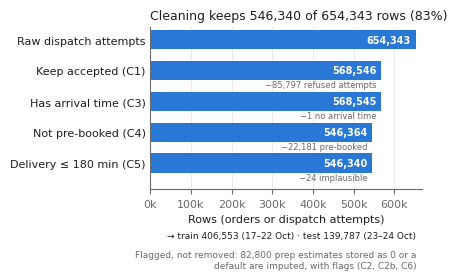

In [27]:
# --- Cleaning funnel (slide 4; the report uses the before -> after table in §5)
labels = ["Raw dispatch attempts", "Keep accepted (C1)", "Has arrival time (C3)",
          "Not pre-booked (C4)", "Delivery ≤ 180 min (C5)"]
notes = ["", "−85,797 refused attempts", "−1 no arrival time", "−22,181 pre-booked", "−24 implausible"]
n = table["rows after"].tolist()
fig, ax = plt.subplots(figsize=(3.5, 2.1))
y = range(len(n))[::-1]
ax.barh(list(y), n, height=0.62, color=BLUE)
for yi, v, note in zip(y, n, notes):
    ax.text(v * 0.98, yi, f"{v:,}", ha="right", va="center", color="white", fontsize=7, fontweight="bold")
    if note:
        ax.text(v * 0.98, yi - 0.47, note, ha="right", va="center", color=MUTED, fontsize=6)
ax.set_yticks(list(y), labels)
ax.set_xlim(0, n[0] * 1.02); ax.set_ylim(-0.85, len(n) - 0.6)
ax.set_xlabel("Rows (orders or dispatch attempts)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.set_title(f"Cleaning keeps {n[-1]:,} of {n[0]:,} rows ({n[-1] / n[0]:.0%})", loc="left", fontsize=9, color=INK)
kept = load_table()
flagged = int(kept["prep_missing"].sum())
n_train, n_test = int((kept["day"] <= 20221022).sum()), int((kept["day"] > 20221022).sum())
ax.text(0.98, -0.3, f"→ train {n_train:,} (17–22 Oct) · test {n_test:,} (23–24 Oct)", transform=ax.transAxes,
        ha="right", fontsize=6.5, color=INK)
ax.text(0.98, -0.38, f"Flagged, not removed: {flagged:,} prep estimates stored as 0 or a\ndefault are imputed, with flags (C2, C2b, C6)",
        transform=ax.transAxes, ha="right", va="top", fontsize=6.5, color=MUTED)
save(fig, "cleaning_funnel")
plt.show()

**Slide 4.** The −1 and −24 steps are invisible at this scale, which is fine for a slide; the report uses the
before → after table (§5). Rows with missing prep estimates are kept, imputed and flagged, so they don't shrink the
funnel; the note under it says so.

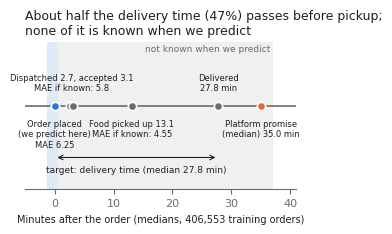

pickup / delivery (medians): 47.2%


In [28]:
# --- Figure 1: order timeline, what is known at prediction time (slide 3; leakage numbers for backup B2)
t = load_table()
t = t[t["day"] <= 20221022]       # training days only
med = t[["dispatch_min", "grab_min", "fetch_min", "delivery_min", "promise_min"]].median()
# CV MAE of the frozen HGB when each time is also given to the model (S5, 03_stages §7); order-time only: 6.25
MAE_IF_KNOWN = {"dispatch/accept": "5.8", "pickup": "4.55", "order": "6.25"}
fig, ax = plt.subplots(figsize=(3.5, 1.9))
ax.axvspan(0.6, med["promise_min"] + 2, color=GRID, alpha=0.6, lw=0, zorder=0)
ax.axvspan(-1.2, 0.6, color=BLUE, alpha=0.15, lw=0, zorder=0)
ax.text(med["promise_min"] + 1.5, 0.82, "not known when we predict", ha="right", fontsize=6.5, color=MUTED)
ax.axhline(0, color=MUTED, lw=1.2, zorder=1)
ax.annotate("", xy=(med["delivery_min"], -0.78), xytext=(0, -0.78), arrowprops=dict(arrowstyle="<->", color=INK, lw=0.8))
ax.text(med["delivery_min"] / 2, -0.9, f"target: delivery time (median {med['delivery_min']:.1f} min)",
        ha="center", va="top", fontsize=6.5, color=INK)
for x, col in [(0, BLUE), (med["dispatch_min"], MUTED), (med["grab_min"], MUTED), (med["fetch_min"], MUTED),
               (med["delivery_min"], MUTED), (med["promise_min"], ORANGE)]:
    ax.plot(x, 0, "o", ms=6, color=col, mec="white", mew=1.2, zorder=3)
labels_tl = [(0, -0.2, f"Order placed\n(we predict here)\nMAE {MAE_IF_KNOWN['order']}"),
             ((med["dispatch_min"] + med["grab_min"]) / 2, 0.2,
              f"Dispatched {med['dispatch_min']:.1f}, accepted {med['grab_min']:.1f}\nMAE if known: {MAE_IF_KNOWN['dispatch/accept']}"),
             (med["fetch_min"], -0.2, f"Food picked up {med['fetch_min']:.1f}\nMAE if known: {MAE_IF_KNOWN['pickup']}"),
             (med["delivery_min"], 0.2, f"Delivered\n{med['delivery_min']:.1f} min"),
             (med["promise_min"], -0.2, f"Platform promise\n(median) {med['promise_min']:.1f} min")]
for x, dy, lab in labels_tl:
    ax.text(x, dy, lab, ha="center", va="bottom" if dy > 0 else "top", fontsize=6, color=INK)
ax.set_xlim(-5, 41); ax.set_ylim(-1.25, 0.95)
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_xlabel(f"Minutes after the order (medians, {len(t):,} training orders)", fontsize=7)
share = med["fetch_min"] / med["delivery_min"]
ax.set_title(f"About half the delivery time ({share:.0%}) passes before pickup;\nnone of it is known when we predict",
             loc="left", fontsize=9, color=INK)
save(fig, "order_timeline")
plt.show()
print(f"pickup / delivery (medians): {share:.1%}")

**Slide 3 (and backup B2):** what we know when we predict. The model only sees the order moment (blue band):
distance, prep estimate, time, area and load. Everything after it (grey) is never an input (C7). About half of the
median delivery passes before pickup. "MAE if known" is the frozen HGB's CV error when that time is added (S5,
`03_stages` §7): knowing the pickup time would cut the error from 6.25 to 4.55 min. The promise (orange) lands
about 7 min after the median delivery, which is why it's a padded promise and not an unbiased ETA.

## 7. Pre-booked orders (S7)
The proposal said we'd analyse these separately. Two questions: why don't they belong with normal orders (Lec 3's
outlier tree), and does leaving them out actually help the model?

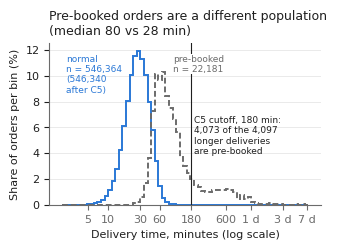

In [29]:
# --- Figure 2: pre-booked orders are a different population (S7; report Data section, justifies C4 and C5)
normal_min, prebook_min = dur[has_arrival & ~pre], dur[has_arrival & pre]
long_all, long_pre = ((dur > 180) & has_arrival).sum(), ((dur > 180) & has_arrival & pre).sum()
fig, ax = plt.subplots(figsize=(3.5, 2.1))
bins = np.logspace(np.log10(2), np.log10(10_500), 70)       # log-spaced bins, 2 min to 7.3 days
for s, col, ls in [(normal_min, BLUE, "-"), (prebook_min, MUTED, (0, (3, 1.5)))]:
    ax.hist(s, bins=bins, weights=np.full(len(s), 100 / len(s)), histtype="step", color=col, lw=1.4, ls=ls)
ax.axvline(180, color=INK, lw=0.8)
top = ax.get_ylim()[1]
ax.text(2.3, top * 0.93, f"normal\nn = {len(normal_min):,}\n({(normal_min <= 180).sum():,}\nafter C5)", ha="left", va="top", fontsize=6.5, color=BLUE)
ax.text(95, top * 0.93, f"pre-booked\nn = {len(prebook_min):,}", va="top", fontsize=6.5, color=MUTED,
        bbox=dict(fc="white", ec="none", pad=0.5))
ax.text(200, top * 0.55, f"C5 cutoff, 180 min:\n{long_pre:,} of the {long_all:,}\nlonger deliveries\nare pre-booked",
        fontsize=6.5, color=INK, va="top")
ax.set_xscale("log"); ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xticks([5, 10, 30, 60, 180, 600, 1440, 4320, 10080], ["5", "10", "30", "60", "180", "600", "1 d", "3 d", "7 d"])
ax.set_xlabel("Delivery time, minutes (log scale)"); ax.set_ylabel("Share of orders per bin (%)")
ax.grid(axis="y", color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.set_title(f"Pre-booked orders are a different population\n(median {prebook_min.median():.0f} vs {normal_min.median():.0f} min)",
             loc="left", fontsize=9, color=INK)
save(fig, "delivery_time_by_prebook")
plt.show()

In [30]:
# Pre-booked vs normal, all accepted orders with an arrival time. Description only, nothing here is fit
timed = acc[has_arrival]
is_pre = (timed["is_prebook"] == 1).rename("pre-booked")


def gap(start, end):
    """Minutes between two timestamps, NaN where either is stored as 0."""
    return ((timed[end] - timed[start]) / 60).where((timed[start] != 0) & (timed[end] != 0))


km = haversine_km(timed["sender_lat"] / 1e6, timed["sender_lng"] / 1e6, timed["recipient_lat"] / 1e6, timed["recipient_lng"] / 1e6)
medians = pd.DataFrame({
    "order to dispatch (min)": gap("platform_order_time", "dispatch_time"),
    "dispatch to arrival (min)": gap("dispatch_time", "arrive_time"),
    "order to arrival, the delivery time (min)": gap("platform_order_time", "arrive_time"),
    "order to promise (min)": gap("platform_order_time", "estimate_arrived_time"),
    "dispatch to promise (min)": gap("dispatch_time", "estimate_arrived_time"),
    "distance (km)": km,
}).groupby(is_pre).median().T
promise_at = pd.to_datetime(timed["estimate_arrived_time"], unit="s")
prep_after = timed["estimate_meal_prepare_time"] - timed["platform_order_time"]
shares = 100 * pd.DataFrame({
    "promise on a 10-minute mark (%)": (promise_at.dt.second == 0) & (promise_at.dt.minute % 10 == 0),
    "arrived by the promise (%)": timed["arrive_time"] <= timed["estimate_arrived_time"],
    "placed on an earlier day than dt (%)": placed_day[has_arrival] < timed["dt"],
    "no usable prep estimate (%)": (timed["estimate_meal_prepare_time"] == 0) | (prep_after < 300),
}).groupby(is_pre).mean().T
counts = pd.DataFrame({"accepted orders": is_pre.groupby(is_pre).size(),
                       "deliveries over 3 h": (dur[has_arrival] > 180).groupby(is_pre).sum()}).T
compared = pd.concat([counts, medians, shares]).rename(columns={False: "normal", True: "pre-booked"})

for name, rows in [("normal", ~is_pre), ("pre-booked", is_pre)]:
    rho_slot = gap("platform_order_time", "arrive_time")[rows].corr(gap("platform_order_time", "estimate_arrived_time")[rows], method="spearman")
    print(f"{name}: Spearman, delivery time vs time to the promise {rho_slot:.2f}")
order_cols = ["platform_order_time", "order_push_time", "dispatch_time", "grab_time", "fetch_time", "arrive_time"]
timed_pre = timed[is_pre]
out_of_order = sum(((timed_pre[a] > timed_pre[b]) & (timed_pre[a] != 0) & (timed_pre[b] != 0)).sum()
                   for a, b in zip(order_cols, order_cols[1:]))
print(f"pre-booked orders with timestamps out of order: {out_of_order}")

# Is the extra time after dispatch only distance or hour? Compare with normal orders in the same distance band and dispatch hour
after = pd.DataFrame({"after": gap("dispatch_time", "arrive_time"), "band": pd.cut(km, [0, 1, 2, 3, 20]),
                      "hour": pd.to_datetime(timed["dispatch_time"], unit="s", utc=True).dt.tz_convert("Asia/Shanghai").dt.hour})
usual = after[~is_pre].groupby(["band", "hour"], observed=True)["after"].median().rename("usual")
matched = after[is_pre].join(usual, on=["band", "hour"])
print(f"after dispatch, same distance band and hour: {(matched['after'] - matched['usual']).median():+.1f} min vs normal orders")
compared.round(1)

normal: Spearman, delivery time vs time to the promise 0.71
pre-booked: Spearman, delivery time vs time to the promise 0.98
pre-booked orders with timestamps out of order: 0
after dispatch, same distance band and hour: +13.4 min vs normal orders


pre-booked,normal,pre-booked
accepted orders,546364.0,22181.0
deliveries over 3 h,24.0,4073.0
order to dispatch (min),2.7,37.4
dispatch to arrival (min),24.1,38.8
"order to arrival, the delivery time (min)",27.9,79.9
order to promise (min),35.1,83.6
dispatch to promise (min),30.4,45.0
distance (km),1.5,1.7
promise on a 10-minute mark (%),0.2,99.4
arrived by the promise (%),85.2,79.3


In [31]:
# Does leaving them out help? Training days only, same forward folds as the models; the test days stay untouched
from common import split
from common.config import TRAIN_DAYS
from common.evaluate import paired_bootstrap
from common.features import FEATURE_SETS, FeatureSet
from experiments.run import fit_predict

everything = load_table(modelling=False)
everything = everything[everything["day"].isin(TRAIN_DAYS) & everything["delivery_min"].notna()]
normal = everything[(everything["is_prebook"] == 0) & ~everything["implausible"]]
booked = everything[everything["is_prebook"] == 1]
base = FEATURE_SETS["base"]
with_flag = FeatureSet("with_flag", (*base.numeric, "is_prebook"), base.categorical)


def abs_err(y, pred):
    return np.abs(y.to_numpy() - pred)


rows = {}
for model in ["elasticnet", "hgb"]:
    errors = {k: [] for k in ["excluded", "mixed in", "mixed in, under 3 h", "mixed in, flagged", "on pre-booked", "promise on pre-booked"]}
    for _, fit, val in split.forward_folds(normal):
        fit_booked = booked[booked["day"].isin(fit["day"].unique())]
        short_booked = fit_booked[fit_booked["delivery_min"] <= 180]   # keeps C5 if only C4 were dropped
        val_booked = booked[booked["day"] == val["day"].iloc[0]]
        for name, fs, rows_fit in [("excluded", base, fit),
                                   ("mixed in", base, pd.concat([fit, fit_booked])),
                                   ("mixed in, under 3 h", base, pd.concat([fit, short_booked])),
                                   ("mixed in, flagged", with_flag, pd.concat([fit, fit_booked]))]:
            errors[name].append(abs_err(val["delivery_min"], fit_predict(model, fs, rows_fit, val)[0]))
        errors["on pre-booked"].append(abs_err(val_booked["delivery_min"], fit_predict(model, base, fit, val_booked)[0]))
        errors["promise on pre-booked"].append(abs_err(val_booked["delivery_min"], val_booked["promise_min"].to_numpy()))
    errors = {k: np.concatenate(v) for k, v in errors.items()}
    rows[model] = {k: v.mean() for k, v in errors.items()}
    for name in ["mixed in", "mixed in, under 3 h", "mixed in, flagged"]:
        boot = paired_bootstrap(pd.Series(errors[name]), pd.Series(errors["excluded"]))
        print(f"{model}, {name} minus excluded: {boot['diff']:+.3f} (95% CI {boot['ci95'][0]:+.3f} to {boot['ci95'][1]:+.3f})")
print(f"pre-booked rows on the training days: {len(booked):,}")
pd.DataFrame(rows).round(2).rename_axis("MAE (min); first four are on normal orders")

elasticnet, mixed in minus excluded: +2.470 (95% CI +2.438 to +2.502)
elasticnet, mixed in, under 3 h minus excluded: +0.396 (95% CI +0.387 to +0.405)
elasticnet, mixed in, flagged minus excluded: +1.378 (95% CI +1.358 to +1.398)
hgb, mixed in minus excluded: +2.609 (95% CI +2.570 to +2.648)
hgb, mixed in, under 3 h minus excluded: +0.485 (95% CI +0.473 to +0.496)
hgb, mixed in, flagged minus excluded: +0.497 (95% CI +0.485 to +0.508)
pre-booked rows on the training days: 16,894


,elasticnet,hgb
MAE (min); first four are on normal orders,,
excluded,6.60,6.28
mixed in,9.07,8.89
"mixed in, under 3 h",7.00,6.76
"mixed in, flagged",7.98,6.77
on pre-booked,157.50,159.29
promise on pre-booked,7.35,7.35


**Report Data section (S7):** 22,181 accepted orders (3.9%) are pre-booked: the customer picks a later slot (99.4% of
their promises fall on a 10-minute mark, vs 0.2% of normal orders). Lec 3's outlier tree puts them under "different
population". They aren't errors: no timestamps are out of order, and 79% arrive by the promised time. They aren't
rare extremes of normal orders either, because their delivery time follows the chosen slot (Spearman 0.98 with time
to the promise, 0.71 for normal orders). Dispatch waits a median 37 min vs 3, so the median "delivery time" is 80 min
vs 28, and they hold 4,073 of the 4,097 deliveries over 3 h.

After dispatch they take about 15 min longer (13 at the same distance and hour), matching the extra 15 min they
have before the promise (45 vs 30). That fits couriers working to the slot, but we can't prove it.

**Decision (C4):** exclude them from modelling. Leaving them out helps: boosting CV MAE on normal orders is 6.28, vs
6.76 with the pre-booked orders under 3 h mixed in, 6.77 with all of them plus an `is_prebook` flag, and 8.88 with
all of them and no flag. A model trained on normal orders is no use for them either (MAE 159 min vs 7 for the
promise), so it doesn't apply to pre-booked orders. A separate model is out of scope.

## 8. Data quality dimensions (Lec 2)
Lec 2's seven dimensions, with the evidence from this notebook.

| Dimension | Status | Evidence |
|---|---|---|
| Completeness | Good, after decoding two missing codes | No NaNs, but 0 means missing: 85,797 refused-attempt zeros, 9,874 prep times, 1 arrival (§2). Prep "estimates" under 5 min are defaults too (75,361 orders, C2b). 15.2% of orders have no usable estimate |
| Validity | Good | Coordinates in a tight box; timestamps all within 11–24 Oct 2022; flags are 0/1 |
| Accuracy | Caution | Coordinates shifted for privacy; prep is only an estimate (pickup beats 55% of real estimates); 24 implausible durations |
| Consistency | Good, two definitions to state | No timestamp-order violations; `dt` differs from the placement date for 1,758 orders; `is_weekend` follows the placement date |
| Uniqueness | Good | No duplicate rows; one row per accepted order; every refused attempt links to an accepted order |
| Timeliness | Limitation | October 2022 data: fine for research, but a real model would need recent data |
| Representativeness | Main limitation | One city, 8 days, one weekend, no pre-booked orders. Results describe normal orders in this city that week |

## 9. Conclusion
The raw file has 654,343 dispatch attempts but 568,546 orders. The 85,797 refused attempts all repeat an order
someone else accepted, so dropping them (C1) loses nothing. Missing values are stored as 0; decoding them leaves
one order without a target (C3) and 9,874 without a prep estimate (C6, F3). A second missing code hides in the
prep column: "estimates" under 5 min are system defaults, so C2b treats 75,361 more orders as missing. Pre-booked
orders are a different population (median 79.9 vs 27.9 min, and 4,073 of the 4,097 deliveries over 3 h), so C4
excludes them (§7), and C5 then removes only 24 more. The modelling table has **546,340 orders**, matching
`load_table()`.

Not found: duplicate rows, timestamp-order violations, stray coordinates, constant columns.

**Next (S4):** (1) C1–C5 hold up. (2) Missing prep isn't random but costs only 2–4 min at the same distance, so
C6 + F3 stay. (3) Call `da_id` "areas", not districts, since they can overlap. (4) Define `dt` and `is_weekend`
in the report. (5) Check the 181 deliveries under 5 min against distance. (6) One city and one week is the main
limitation.